# Anatomy, trajectory and network view of a two-hidden-layer run

One notebook for every **two-hidden-layer** run of the design series: runs 42-46 (first notebook) and 55-78 (notebook 2), including the
symmetrised-flow runs (72-78) and the x1-output-rate variants of 74 / 75 / 77 / 78. `RUN` in the setup cell selects the run and `EPOCH`
the snapshot for the anatomy (default: the last stored). The per-run summaries and findings stay in notebook 2; the analysis code lives in
`layer_lenses.run_analysis` (loading, end-of-run numbers, trajectory plots, network view) and in this notebook's cells (the anatomy).

Sections: 0 end-of-run numbers, trajectory plots and the network view; 1 the first layer as a feature bank (and the shared ancestor tilt of
each pole pair); 2 the second layer in the feature basis (vetoes and backgrounds); 3 the level-3 units as leaf detectors; 4 the lower-level
units; 5 the readout: contributions, ablations, the decision near the boundary, and the sharp-veto limit; 6 the 62 x 60 paths: active-region statistics (leaf-cell histogram, path weight, effective linear function, label correlation) at `EPOCH` and over training. The written findings are for run
56 at its last epoch; every table and plot recomputes for the selected run. Runs that did not converge to the designed solution are
handled (cells report missing rows and units without a cue veto instead of assuming the complete structure).

Conventions: a row's *feature* is `f_r(x) = ||w_r|| relu(+-a_n(x))` with `a_n = u_n . x` for the normal the row is closest to; a unit's
*cue reading* of leaf m is `c_u(m) = sum over the two cue rows of m of W2[u, row] x pole x ||row||`; its *side-contrast* on node j is
`C_u(j) = sum over leaves m under j of side_j(m) c_u(m)`.


In [109]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import NODE_LEVEL, node_ancestors, HIERARCHY_TARGETS
from layer_lenses.init_sweep import SweepRunSpec, build_data, load_tree
from layer_lenses.run_analysis import AnalysisContext, load_replay_run, findings_table, trajectory_plots, network_view
np.set_printoptions(linewidth=200, precision=2, suppress=True); pd.set_option("display.width", 220)
RUNS = {42: "hierarchy_equiv2L_62", 43: "hierarchy_equiv2L_62_outx41", 44: "hierarchy_equiv2L_62_outfrozen", 45: "hierarchy_equiv2L_62_sadam01", 46: "hierarchy_equiv2L_62_sadam03",   # first notebook: run 38 without the third layer (free training, 1M points)
        55: "hd2_run55_phased2_2L_10M", 56: "hd2_run56_phased2_2L_outx80_10M", 57: "hd2_run57_phase1_proj_u0", 58: "hd2_run58_phase1_proj_u1", 59: "hd2_run59_sgd_lr02_2000", 60: "hd2_run60_sgd_lr1_1000",     # notebook 2: phased, 10M points; 60 = the anchor
        61: "hd2_run61_phase1_randcue_n1", 62: "hd2_run62_cuenoise_r1", 63: "hd2_run63_gradcue", 67: "hd2_run67_symcue_pilot", 68: "hd2_run68_symcue_outx1", 69: "hd2_run69_symcue_flipped", 70: "hd2_run70_symcue_partner", 71: "hd2_run71_symcue_partner_half",
        72: "hd2_run72_sym_pgf_phase1", 73: "hd2_run73_sym_pgf_two_phase", 74: "hd2_run74_sym_pgf_run60", 75: "hd2_run75_sym_pgf_run60_partner", 76: "hd2_run76_sym_pgf_one_phase", 77: "hd2_run77_sym_pgf_run60_one_phase", 78: "hd2_run78_sym_pgf_run60_partner_one_phase",   # symmetrised flow (72-78)
        "74x1": "hd2_run74_sym_pgf_run60_outx1", "75x1": "hd2_run75_sym_pgf_run60_partner_outx1", "77x1": "hd2_run77_sym_pgf_run60_one_phase_outx1", "78x1": "hd2_run78_sym_pgf_run60_partner_one_phase_outx1",
        79: "hd2_run79_alpha_a3_1.5_2ph", 80: "hd2_run80_alpha_a3_1.5_1ph", 81: "hd2_run81_alpha_a3_4_2ph", 82: "hd2_run82_alpha_a3_4_1ph", 83: "hd2_run83_alpha_blocks_x0.5_2ph", 84: "hd2_run84_alpha_blocks_x0.5_1ph", 
        85: "hd2_run85_alpha_blocks_x2_2ph", 86: "hd2_run86_alpha_blocks_x2_1ph", 87: "hd2_run87_alpha_a6_0.1_2ph", 88: "hd2_run88_alpha_a6_0.1_1ph", 89: "hd2_run89_alpha_a5_0_2ph", 90: "hd2_run90_alpha_a5_0_1ph", 
        91: "hd2_run91_alpha_veto_2_2ph", 92: "hd2_run92_alpha_veto_2_1ph", 93: "hd2_run93_alpha_readout_0.4_1.6_2ph", 94: "hd2_run94_alpha_readout_0.4_1.6_1ph", 
        95: "hd2_run95_alpha_a11_8_2ph", 96: "hd2_run96_alpha_a11_8_1ph", 97: "hd2_run97_sym_pgf_run73_cont", 98: "hd2_run98_sym_pgf_run79_cont",
        99: "hd2_run99_cuebias_p2_b0.5", 100: "hd2_run100_cuebias_p2_b0.25", 101: "hd2_run101_cuebias_p2_b0.1", 102: "hd2_run102_cuebias_p2_b0.05", 103: "hd2_run103_cuebias_p2_b0.02", 104: "hd2_run104_cuebias_p1_b0.25", 105: "hd2_run105_cuebias_p1_b0.1", 106: "hd2_run106_cuebias_p1_b0.05"}   # cue-bias sweeps (notebook 2 section 37)   # run 79 continued   # run 73 continued   # alpha sweep A (notebook 2 section 34)   # the x1-output-rate variants       # 72: symmetrised-gradient flow (phase 1 of run 70)
RUN = 79                                                                                                                                  # <- select the run
RESULTS = Path("../results/designed_init"); RUNDIR = RESULTS / RUNS[RUN]; tree = load_tree(RUNDIR / "tree.npz"); U = tree.w_list
ctx = AnalysisContext(RESULTS, tree=tree)                                                                                                 # test sample (seed 999777, 100k points) for the section-0 helpers
sr, run = load_replay_run(ctx, RUNS[RUN], [62, 60])                                                                                      # trajectory of all layers at every stored epoch
z = np.load(RUNDIR / "replay/weights.npz"); EPOCHS = list(z["epochs"]); EPOCH = EPOCHS[-1]                                                     # <- select the snapshot
meta = pickle.load(open(RUNDIR / "replay/meta.pkl", "rb")); ups = np.array(meta["design"]["unit_path_sign"]); ubs = np.array(meta["design"]["unit_block_sign"]); unode = np.array(meta["design"]["unit_node"])
N_ROWS, N_UNITS = z["w__hidden_layers.0.weight"].shape[1], z["w__hidden_layers.1.weight"].shape[1]; assert "w__hidden_layers.2.weight" not in z.files, "this notebook is for two-hidden-layer runs"
x, y = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree); y = y.astype(np.float64); A = x @ U.T      # a_n(x) for the 31 normals
def reach4(A):
    node = np.zeros(len(A), int)
    for lvl in range(4): node = 2 * node + 1 + (A[np.arange(len(A)), node] > 0)
    return node
m_reached = reach4(A); assert np.array_equal(np.sign(A[np.arange(len(A)), m_reached]), y); am = A[np.arange(len(A)), m_reached]
utype = np.array([f"({'+' if b > 0 else '-'}B,{'+' if s > 0 else '-'})" for b, s in zip(ubs, ups)])
def use_epoch(e):
    """Load the snapshot of epoch e into the notebook globals: weights, rows as (node, pole) features, forward pass, readout."""
    g = globals(); g["EPOCH"] = e; W1, W2, Wo = (z[k][EPOCHS.index(e)].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__output_layer.weight"])
    nrm = np.linalg.norm(W1, axis=1); Cos = W1 / nrm[:, None] @ U.T; top = np.abs(Cos).argmax(1); pole = np.sign(Cos[np.arange(N_ROWS), top]).astype(int); cos = np.abs(Cos).max(1)
    g.update(W1=W1, W2=W2, Wo=Wo, nrm=nrm, Cos=Cos, top=top, pole=pole, cos=cos, rname=np.array([f"{'+' if pole[r] > 0 else '-'}u{top[r]}" for r in range(N_ROWS)]), Weff=W2 * nrm[None, :],
             F=np.maximum(pole[None, :] * A[:, top], 0), h1=np.maximum(x @ W1.T, 0))
    g["h2"] = np.maximum(g["h1"] @ W2.T, 0); g["readout"] = Wo.ravel(); g["logit"] = g["h2"] @ g["readout"]; g["contrib"] = g["h2"] * g["readout"][None, :]
    print(f"run {RUN} ({RUNS[RUN]}), epoch {e} of {EPOCHS[-1]}: test error {((g['logit'] >= 0) != (y > 0)).mean():.5f} on {len(y)} points; logit rms {np.sqrt((g['logit'] ** 2).mean()):.1f}; "
          f"readout sign = path sign on {(np.sign(g['readout']) == ups).mean():.2f} of units, |readout| mean {np.abs(g['readout']).mean():.1f}; rows at |cos| > 0.95 with a normal: {(cos > 0.95).sum()} / {N_ROWS}")
from layer_lenses.designed_init import cue_row_identity
_cid = cue_row_identity(z["w__hidden_layers.0.weight"][0].astype(np.float64), tree, meta["design"]["cue_rows"])                                  # designed cue identity at init: (node, pole) -> row
col_label = np.array([f"p{r}" for r in range(N_ROWS)], dtype=object)
for (n_, p_), r in _cid.items(): col_label[r] = f"{'+' if p_ > 0 else '-'}u{n_}"
use_epoch(EPOCH)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
run 79 (hd2_run79_alpha_a3_1.5_2ph), epoch 1000 of 1000: test error 0.00781 on 100000 points; logit rms 14.4; readout sign = path sign on 1.00 of units, |readout| mean 67.8; rows at |cos| > 0.95 with a normal: 30 / 62


## 0. End-of-run numbers, trajectory and network view

`findings_table` gives the end state (loss, both test-error rules, coverage, probe outcomes); `trajectory_plots` the loss, test error and
node coverage over the stored epochs, every probe's signed cosine to its designed target, and the alignment series of the chosen
first-layer neurons against the chosen ODT nodes; `network_view` the layered graph at `GRAPH_EPOCH` with the rows labelled by their closest
normal. `TRAJ_STRIDE` thins the per-epoch forward passes for long runs.


In [110]:
rec, hier = findings_table(ctx, run); display(rec.to_frame(run["tag"]))
if run["summary"] is not None: print("summary.csv:", {k: run["summary"][k] for k in run["summary"].index if k in ("final_epoch_loss", "test_error_end", "nodes_covered_end", "wall_min")})


,hd2_run79_alpha_a3_1.5_2ph
final epoch loss,0.0632
test error (logit >= 0),0.0078
test error (strict),0.0078
zero-logit fraction,0.0
negative output weights,30
epochs to 0.3 / 0.1 / 0.05,52 / 187 / None
aligned rows,30 / 62
nodes covered,"15 / 31, missing [15, 16, 17, 18, 19, 20, 21, ..."
own-probe nodes / intended / opposite,15 / 15 / 0
missed by own probes,[]


summary.csv: {'final_epoch_loss': np.float64(0.0632177391126751), 'test_error_end': np.float64(0.0078250002115964), 'nodes_covered_end': np.int64(15), 'wall_min': np.float64(32.375246636072795)}


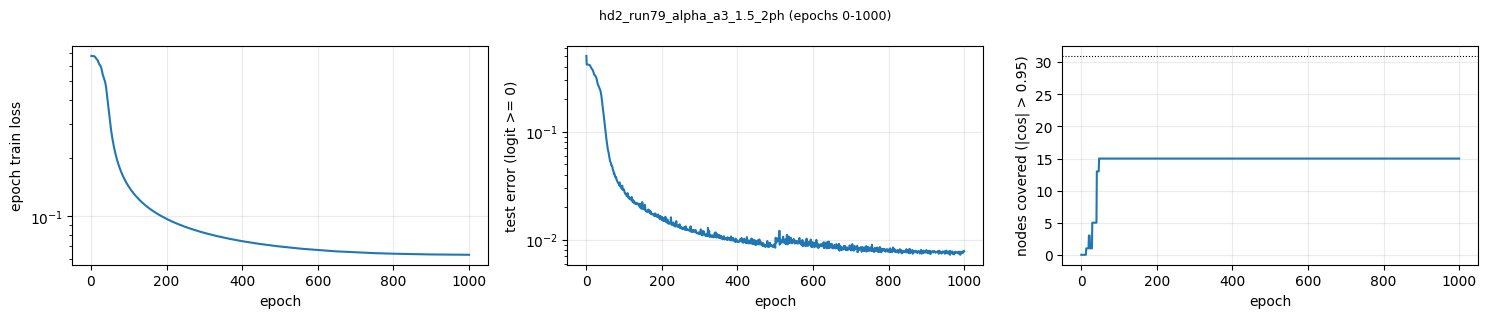

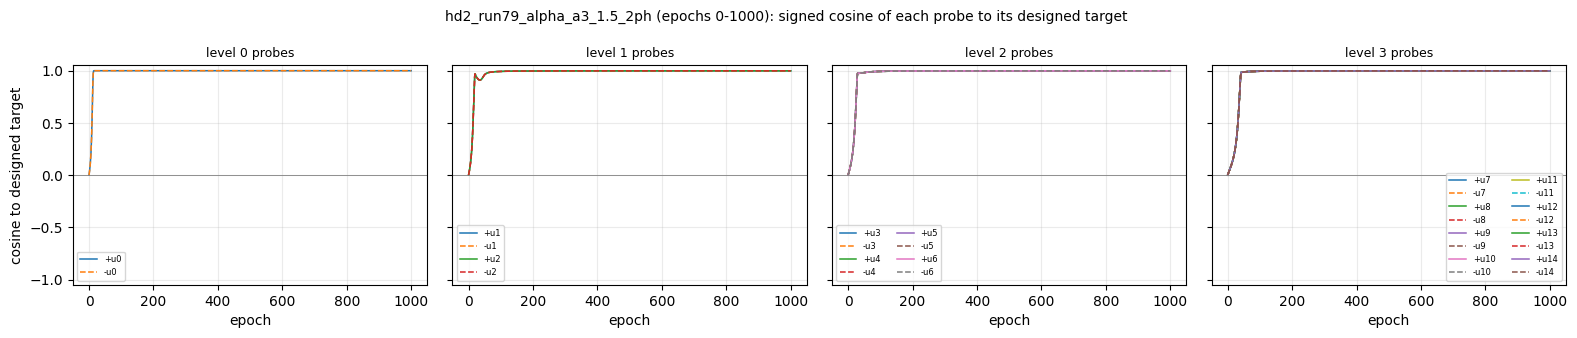

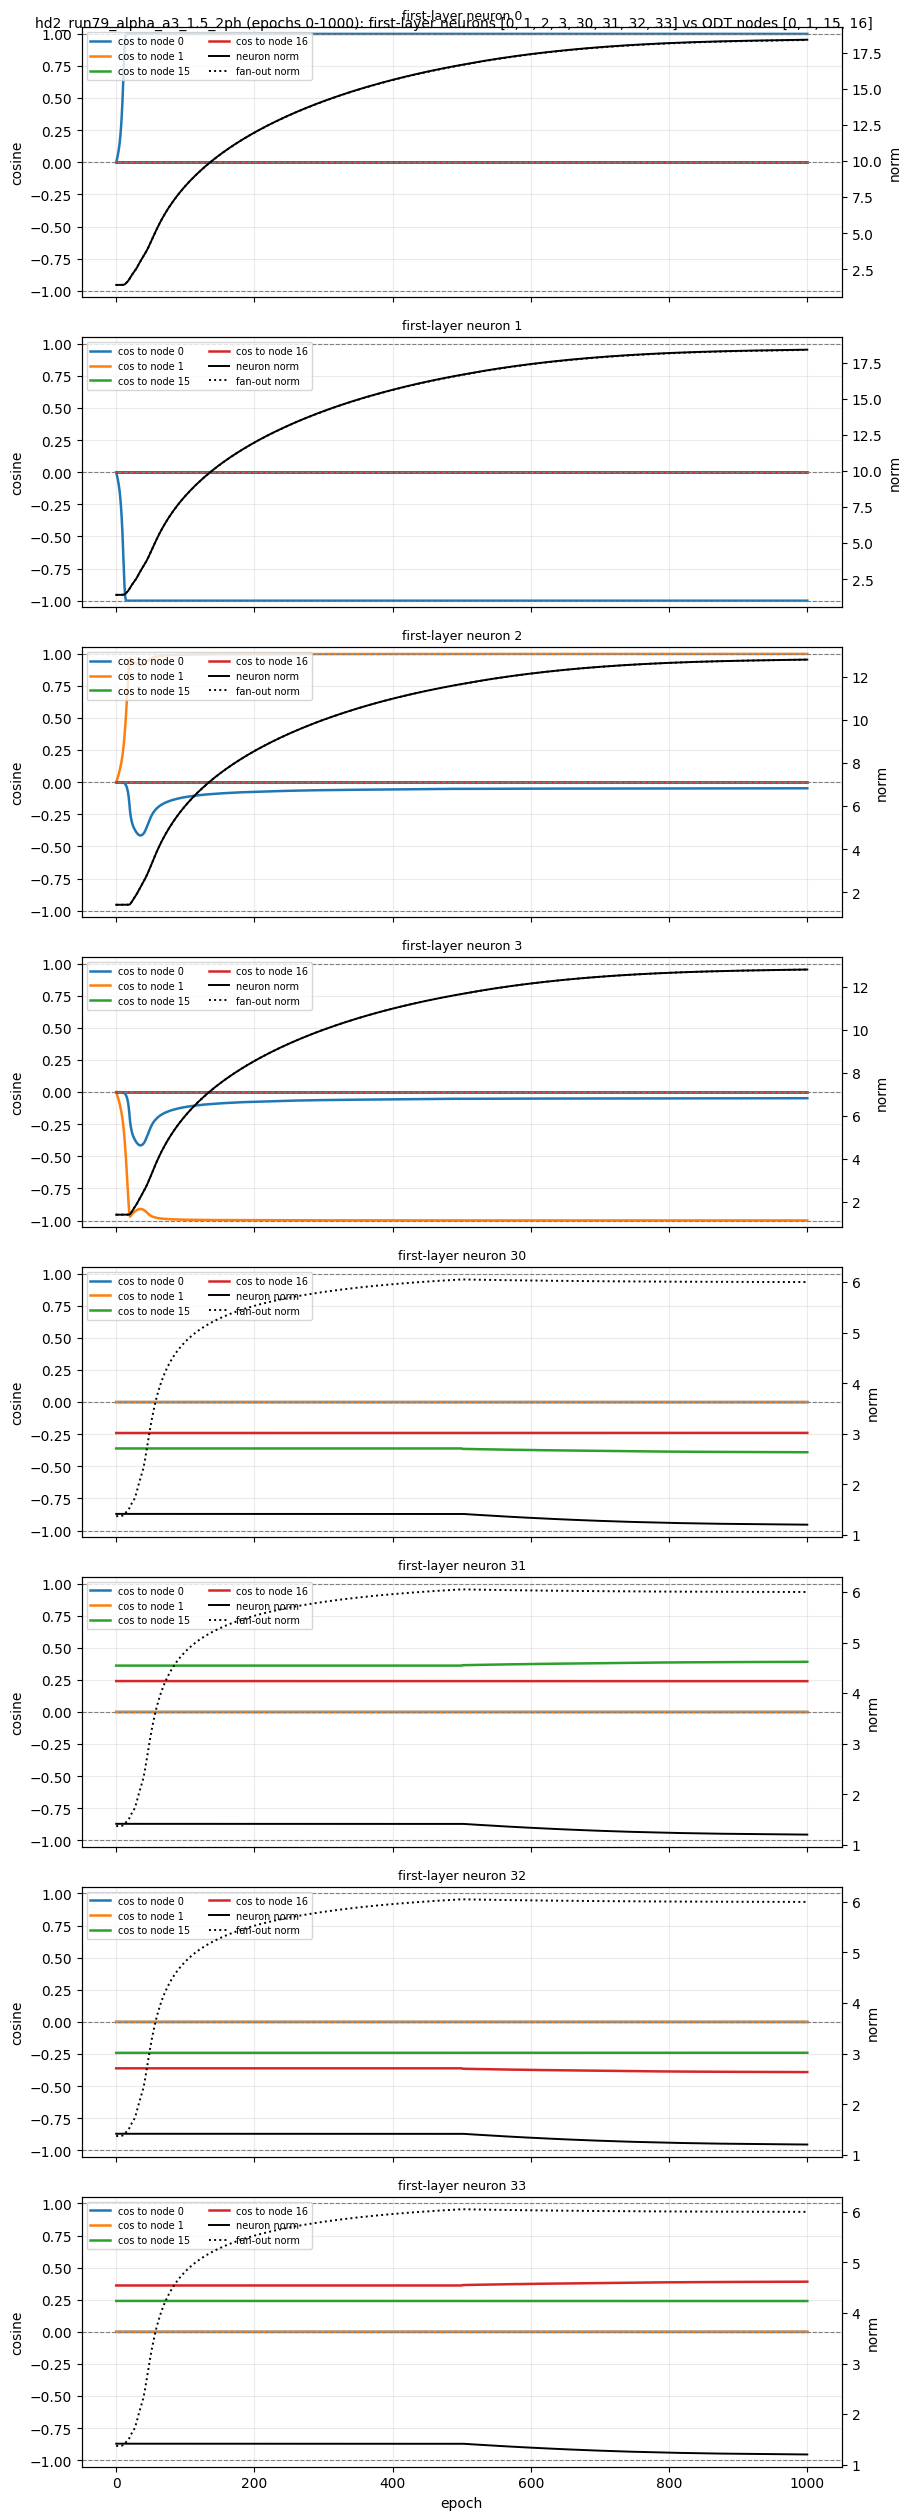

In [112]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]                      # first-layer rows to follow (probes 0-3 = +-u_0, +-u_1; rows 30-33 = the first two cues)
TRAJ_STRIDE = 1
series = trajectory_plots(ctx, run, NEURON_IDS, node_ids=None, stride=TRAJ_STRIDE, start_epoch=0, end_epoch=1000)


79
Visible edges: 2108 / 3780
First-layer aligned nodes: 30 / 62


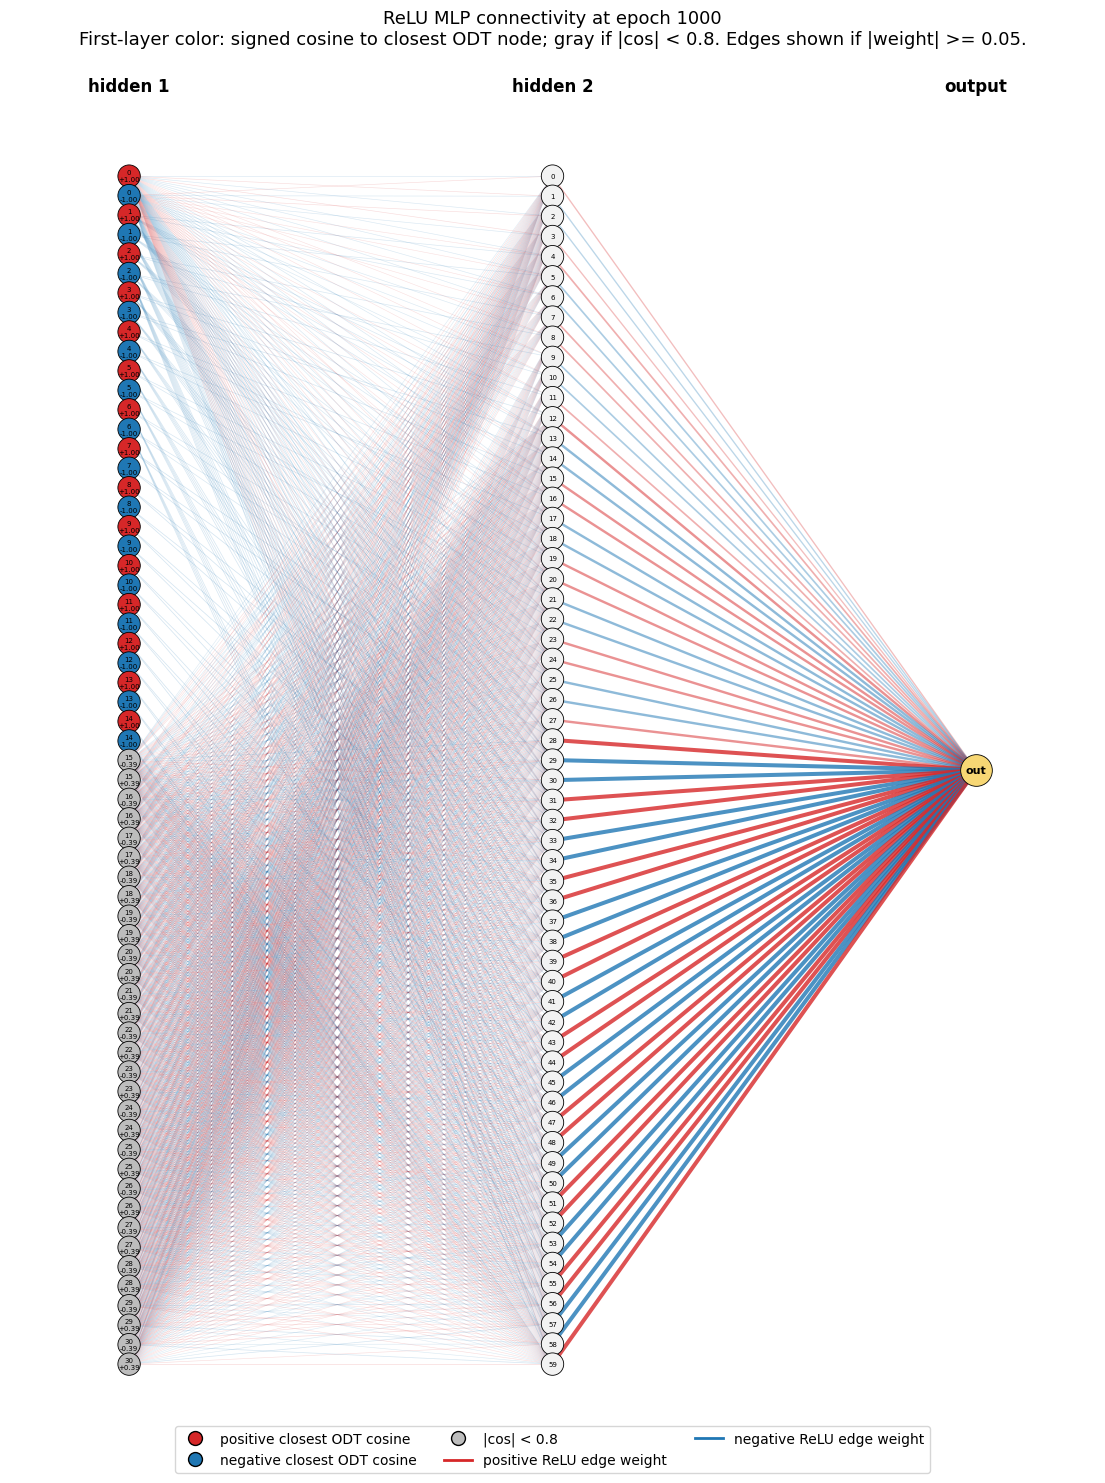

,row,group,designed_target,closest_node,level,signed_cos,norm
0,1,probe,"(0, -1)",0,0,-1.000,18.41
1,0,probe,"(0, 1)",0,0,1.000,18.41
2,3,probe,"(1, -1)",1,1,-0.999,12.81
3,2,probe,"(1, 1)",1,1,0.999,12.81
4,5,probe,"(2, -1)",2,1,-0.999,12.81
5,4,probe,"(2, 1)",2,1,0.999,12.81
6,7,probe,"(3, -1)",3,2,-0.999,9.71
7,6,probe,"(3, 1)",3,2,0.999,9.71
8,9,probe,"(4, -1)",4,2,-0.999,9.71
9,8,probe,"(4, 1)",4,2,0.999,9.71


In [114]:
GRAPH_EPOCH = 1000
print(RUN)
table = network_view(ctx, run, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05); display(table)


## 1. The first layer as a bank of one-sided features on the tree's normals


In [64]:
rows = pd.DataFrame({"row": range(N_ROWS), "kind": ["probe"] * 30 + ["cue"] * 32 + ["spare"] * (N_ROWS - 62), "node": top, "pole": pole, "level": NODE_LEVEL[top], "norm": nrm, "cos": cos, "off_span_frac": np.linalg.norm(W1 - (W1 @ U.T) @ U, axis=1) / nrm})
print(rows.groupby(["kind", "level"]).agg(n=("row", "size"), norm_mean=("norm", "mean"), norm_min=("norm", "min"), norm_max=("norm", "max"), cos_min=("cos", "min"), off_span_max=("off_span_frac", "max")).round(3))
pairs = sorted(zip(top[cos > 0.95], pole[cos > 0.95])); complete = sorted(set(pairs)) == sorted((n, p) for n in range(31) for p in (1, -1)) and len(pairs) == 62
print("every (node, pole) pair has exactly one aligned row:", complete)
if not complete:
    from collections import Counter
    cnt = Counter(pairs); print("  (node, pole) pairs with no aligned row:", [(n, p) for n in range(31) for p in (1, -1) if cnt[(n, p)] == 0], "| with several:", {k: v for k, v in cnt.items() if v > 1}, "| rows not aligned (|cos| <= 0.95):", [int(r) for r in np.where(cos <= 0.95)[0]])
print("feature approximation |h1 - norm * relu(pole a_node)| max over points / rows:", np.abs(h1 - F * nrm).max().round(3), "(relative to row norm x typical |a| ~", (nrm.mean() * 0.08).round(2), ")")


              n  norm_mean  norm_min  norm_max  cos_min  off_span_max
kind  level                                                          
cue   4      32      0.934     0.934     0.934    0.624           0.0
probe 0       2     21.065    21.065    21.065    1.000           0.0
      1       4     14.977    14.977    14.977    0.995           0.0
      2       8     11.268    11.268    11.268    0.995           0.0
      3      16      8.273     8.273     8.273    0.996           0.0
every (node, pole) pair has exactly one aligned row: False
  (node, pole) pairs with no aligned row: [(15, 1), (15, -1), (16, 1), (16, -1), (17, 1), (17, -1), (18, 1), (18, -1), (19, 1), (19, -1), (20, 1), (20, -1), (21, 1), (21, -1), (22, 1), (22, -1), (23, 1), (23, -1), (24, 1), (24, -1), (25, 1), (25, -1), (26, 1), (26, -1), (27, 1), (27, -1), (28, 1), (28, -1), (29, 1), (29, -1), (30, 1), (30, -1)] | with several: {} | rows not aligned (|cos| <= 0.95): [30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 

In [65]:
# The residual of each row (unit row minus its +-u_j): in the converged runs the two pole rows of a node share one tilt into the span of the node's ancestors, signed so that t_j . x > 0 on j's subtree.
unit = W1 / nrm[:, None]; tilt = unit - pole[:, None] * U[top]
def side_of(j, m):                      # side of ancestor j on which node m lies (+1: a_j > 0)
    c = m
    while (c - 1) // 2 != j: c = (c - 1) // 2
    return +1 if c == 2 * j + 2 else -1
rec = []
for j in range(31):
    rp = [r for r in range(N_ROWS) if top[r] == j and pole[r] > 0 and cos[r] > 0.95]; rm = [r for r in range(N_ROWS) if top[r] == j and pole[r] < 0 and cos[r] > 0.95]
    if len(rp) != 1 or len(rm) != 1: continue
    a, b = tilt[rp[0]], tilt[rm[0]]; t = (a + b) / 2
    insub = (m_reached == j) if j >= 15 else np.array([j in node_ancestors(k) for k in m_reached]); d = x[insub] @ t
    anc = node_ancestors(j); coef = t @ U.T
    rec.append({"node": j, "level": NODE_LEVEL[j], "cos(tilt+, tilt-)": round(float(a @ b / np.linalg.norm(a) / np.linalg.norm(b)), 3), "in-span fraction": round(float(np.linalg.norm(t @ U.T) / np.linalg.norm(t)), 3),
                "on ancestors fraction": round(float(np.linalg.norm(coef[anc]) / np.linalg.norm(t)), 3) if anc else np.nan, "coef x side > 0 on all ancestors": float(all(coef[a_] * side_of(a_, j) > 0 for a_ in anc)) if anc else np.nan,
                "frac of subtree with t.x > 0": round(float((d > 0).mean()), 3), "mean |t.x| / mean |a_j| on subtree": round(float(np.mean(np.abs(d)) / np.mean(np.abs(A[insub, j]))), 3)})
tilts = pd.DataFrame(rec); print(f"{len(tilts)} of 31 nodes have exactly one aligned row per pole")
if len(tilts): print(tilts.groupby("level").agg({"cos(tilt+, tilt-)": "mean", "in-span fraction": "mean", "on ancestors fraction": "mean", "coef x side > 0 on all ancestors": "mean", "frac of subtree with t.x > 0": "mean", "mean |t.x| / mean |a_j| on subtree": "mean"}).round(3))


15 of 31 nodes have exactly one aligned row per pole
       cos(tilt+, tilt-)  in-span fraction  on ancestors fraction  coef x side > 0 on all ancestors  frac of subtree with t.x > 0  mean |t.x| / mean |a_j| on subtree
level                                                                                                                                                                
0                  0.923             0.034                    NaN                               NaN                         0.499                               0.000
1                  0.995             1.000                    1.0                               1.0                         0.999                               0.096
2                  0.995             1.000                    1.0                               1.0                         1.000                               0.115
3                  0.996             1.000                    1.0                               1.0                  

## 2. The second layer in the feature basis: vetoes and backgrounds

`Weff[u, r] = W2[u, r] ||w_r||` is unit `u`'s weight on the unit-norm feature of row `r`, `relu(pole a_node)` for the node the row sits on.
The heatmap shows the matrix as it is: units U0-U59 (four per node, nodes in heap order, so levels 0 | 1 | 2 | 3 are rows 0-3 | 4-11 |
12-27 | 28-59) against the first-layer rows (probes p0-p29, then the 32 cues labelled by their designed identity +-u_15 .. +-u_30).


run 73 (hd2_run73_sym_pgf_two_phase), epoch 70 of 1500: test error 0.41692 on 100000 points; logit rms 0.4; readout sign = path sign on 1.00 of units, |readout| mean 0.6; rows at |cos| > 0.95 with a normal: 0 / 62


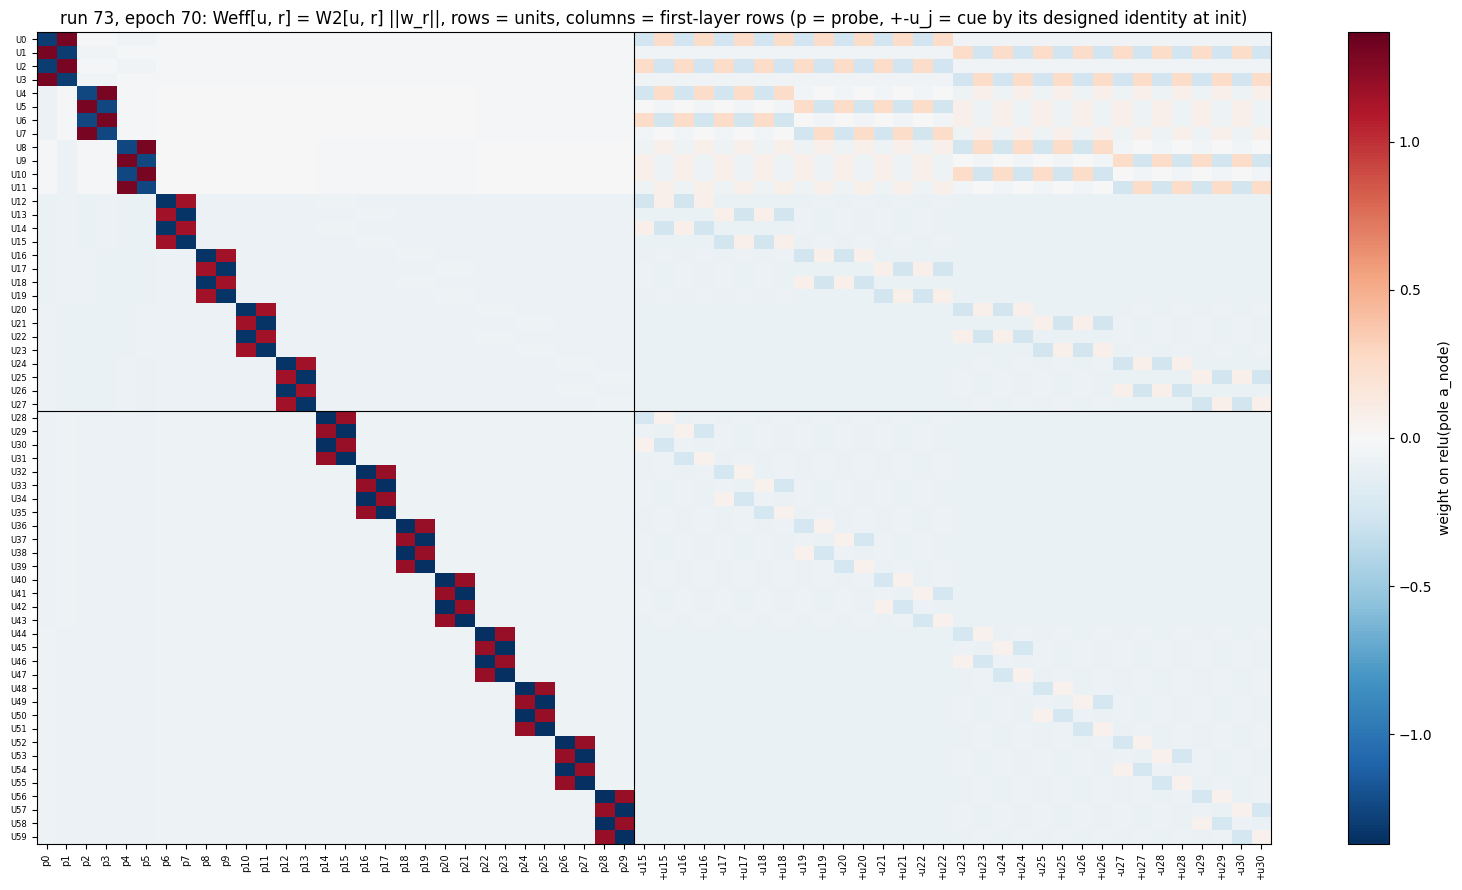

 unit  node  level   type  readout vetoes (weight < -1)  n positive weights  sum of positive weights largest positive  n small negatives (-1, 0)
    0     0      0 (+B,+)      0.5        [(+u0, -1.3)]                   9                     3.32         -u0 1.29                         52
    1     0      0 (+B,-)     -0.5        [(-u0, -1.3)]                   9                     3.32         +u0 1.29                         52
    2     0      0 (-B,-)     -0.5        [(+u0, -1.3)]                   9                     3.32         -u0 1.29                         52
    3     0      0 (-B,+)      0.5        [(-u0, -1.3)]                   9                     3.32         +u0 1.29                         52
    4     1      1 (+B,+)      0.5        [(+u1, -1.2)]                  17                     2.86         -u1 1.30                         44
    5     1      1 (+B,-)     -0.5        [(-u1, -1.2)]                  17                     2.86         +u1 1.30             

In [97]:
EPOCH_VIEW = 70                                   # set to another stored epoch to view the weights there (the rest of the notebook keeps EPOCH); use_epoch(EPOCH) restores the globals
if EPOCH_VIEW != EPOCH: use_epoch(EPOCH_VIEW)
fig, ax = plt.subplots(figsize=(16, 9))

im = ax.imshow(Weff, cmap="RdBu_r", vmin=-np.max(np.abs(Weff)), vmax=np.max(np.abs(Weff)), aspect="auto"); plt.colorbar(im, ax=ax, label="weight on relu(pole a_node)")
ax.set_xticks(range(N_ROWS)); ax.set_xticklabels(col_label, rotation=90, fontsize=7); ax.set_yticks(range(N_UNITS)); ax.set_yticklabels([f"U{u}" for u in range(N_UNITS)], fontsize=6)
ax.axvline(29.5, color="k", lw=0.8)      
ax.axhline(27.5, color="k", lw=0.8)                                                      # probes | cues
ax.set_title(f"run {RUN}, epoch {EPOCH}: Weff[u, r] = W2[u, r] ||w_r||, rows = units, columns = first-layer rows (p = probe, +-u_j = cue by its designed identity at init)"); plt.tight_layout(); plt.show()
# per unit: large negative weights (vetoes) and the sum of positive weights (background)
rec = []
for u in range(N_UNITS):
    w = Weff[u]; vet = [(rname[r], round(float(w[r]), 1)) for r in np.argsort(w) if w[r] < -1.0]; posw = w[w > 0]
    rec.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes (weight < -1)": vet, "n positive weights": int((w > 0).sum()), "sum of positive weights": round(float(posw.sum()), 2), "largest positive": f"{rname[np.argmax(w)]} {w.max():.2f}", "n small negatives (-1, 0)": int(((w < 0) & (w > -1)).sum())})
recipes = pd.DataFrame(rec); print(recipes.to_string(index=False, max_colwidth=110))
if EPOCH_VIEW != EPOCH: use_epoch(EPOCH)


**Findings (run 56, last epoch).** Every unit has the same two-part structure: a few **vetoes**, large negative weights on the *wrong-side* feature of each node
on a path (the design's probe weights, -1 at init, grown 30-80x: 36 at level 0, 31-34 at level 1, 28-47 at level 2, 38-79 at level 3), and a
**background**, dozens of small positive weights summing to 2-3 (level 1-3 units) spread over the other features, plus 10-35 small negatives.
The cue blocks have turned into a 3-unit veto on one cue (level-3 units) or dissolved into the background. The **level-0 units are the
exception**: besides the 36 veto on the wrong side of u_0 they carry a weight of +20 on the *right-side* feature of u_0 (background sum 23),
so they output about 20 |a_0| on their half-space rather than a small constant; their readout is only 7.8. The readout grows with the unit's
level, 7.8 / 15 / 33 / 80, and has the path sign on every unit (no sign flips from init).


## 3. The level-3 units as leaf detectors: one per (level-4 node, label sign)

A level-3 unit of node `j` vetoes the wrong side of `u_0`, of `j`'s level-1 and level-2 ancestors and of `u_j` itself, which confines
it to the region of one child `m` of `j` (a level-4 node), and it vetoes one cue of `m`, which confines it further to one sign of `a_m`,
i.e. to one label. Its readout has the sign of that label.


In [8]:
lvl3 = [u for u in range(N_UNITS) if NODE_LEVEL[unode[u]] == 3]; rows3 = []; no_cue_veto = []
for u in lvl3:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]; cue_vetoes = [r for r in vet_rows if top[r] >= 15 and cos[r] > 0.95]
    if not cue_vetoes: no_cue_veto.append(u); continue
    cue_r = cue_vetoes[0]; m, q = int(top[cue_r]), int(pole[cue_r]); label = -q
    region = m_reached == m; right = region & (np.sign(A[:, m]) == label); wrong = region & (np.sign(A[:, m]) == -label)
    b = F @ np.maximum(w, 0); own = [r for r in range(N_ROWS) if top[r] == m and pole[r] == label and cos[r] > 0.95]
    rows3.append({"unit": u, "node j": unode[u], "type": utype[u], "region m": m, "label served": label, "readout": round(float(readout[u]), 1), "vetoes on path (root..j)": [round(float(w[r]), 0) for r in vet_rows if top[r] < 15], "cue veto": f"{rname[cue_r]} {w[cue_r]:.1f}",
                  "own-sign cue weight": round(float(w[own[0]]), 2) if own else np.nan,
                  "active: region & right sign": round(float((h2[right, u] > 0).mean()), 3), "region & wrong sign": round(float((h2[wrong, u] > 0).mean()), 3), "off region": round(float((h2[~region, u] > 0).mean()), 4),
                  "output on region & right sign: mean": round(float(h2[right, u].mean()), 3), "= background b: corr": round(float(np.corrcoef(h2[right, u], b[right])[0, 1]), 3) if h2[right, u].std() > 0 else np.nan, "b mean / cv": f"{b.mean():.2f} / {b.std() / b.mean():.2f}"})
t3 = pd.DataFrame(rows3)
if len(t3): print(t3.to_string(index=False))
print(f"\n{len(t3)} of {len(lvl3)} level-3 units have a cue veto" + (f"; units without one: {no_cue_veto}" if no_cue_veto else ""))
leaf_complete = len(t3) == 32 and sorted(zip(t3["region m"], t3["label served"])) == sorted((m, s) for m in range(15, 31) for s in (1, -1))
print("each (level-4 node, label) served by exactly one level-3 unit:", leaf_complete, "| readout sign = label served:", bool((np.sign(t3.readout) == t3["label served"]).all()) if len(t3) else None)
if not leaf_complete and len(t3): print("  served cells (region, label) and how many units serve each:", dict(pd.Series(list(zip(t3["region m"], t3["label served"]))).value_counts().sort_index()))
print("veto size by level of the vetoed node (mean over level-3 units): " + ", ".join(f"level {l}: {np.mean([abs(Weff[u, r]) for u in lvl3 for r in range(N_ROWS) if Weff[u, r] < -1 and NODE_LEVEL[top[r]] == l] or [np.nan]):.0f}" for l in range(5)))



0 of 32 level-3 units have a cue veto; units without one: [28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
each (level-4 node, label) served by exactly one level-3 unit: False | readout sign = label served: None
veto size by level of the vetoed node (mean over level-3 units): level 0: nan, level 1: nan, level 2: 1, level 3: 1, level 4: 1


**Findings (run 56, last epoch).** The 32 level-3 units are exactly the 32 (level-4 node, label) detectors: every pair is served once, the readout sign is the
label served, the unit is active on essentially all points of its region with the right label sign (99.7-100%), on about 30% of the points
with the wrong sign (those with |a_m| small, where the 3-unit cue veto has not yet overcome the background; run 53: 9% with a 4-unit veto on
a 1.6-norm cue) and on 0.1% of the points outside its region. The vetoes grow toward the root (77 on the root's wrong side, 51 at level 1,
43 and 39 at levels 2-3, 3 on the cue; run 53: 54 / 36 / 30 / 30 / 4), about 1.4x run 53's. On its (region, sign) set the unit outputs its
background (correlation 0.92), a sum of small positive weights with mean 0.12 and coefficient of variation 0.7 across the sphere, output
0.17 on average (run 53: 0.05 / 0.55 / 0.07), and its readout of +-78 to +-81 turns that into a contribution of about +-13 to the logit.
The own-sign cue carries only a small positive weight (0.1-0.3), so the detector is an indicator of height b(x), not an |a_m| output.


## 4. The 28 lower-level units: coarse region detectors with weak label information


In [9]:
rows_lo = []
for u in [u for u in range(N_UNITS) if NODE_LEVEL[unode[u]] < 3]:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]
    region = np.ones(len(A), bool)
    for r in vet_rows: region &= (pole[r] * A[:, top[r]] <= 0)                                    # the region the vetoes leave: right side of every vetoed node
    depth = max([NODE_LEVEL[top[r]] for r in vet_rows] or [-1]) + 1
    rows_lo.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes": [rname[r] for r in vet_rows], "region: subtree of a node at level": depth, "region fraction": round(float(region.mean()), 3),
                    "active on region": round(float((h2[region, u] > 0).mean()), 3), "active off region": round(float((h2[~region, u] > 0).mean()), 4) if (~region).any() else np.nan, "mean output on region": round(float(h2[region, u].mean()), 3),
                    "corr(output, y) on region": round(float(np.corrcoef(h2[region, u], y[region])[0, 1]), 3) if h2[region, u].std() > 0 else np.nan, "cue weights: sum positive / sum negative": f"{w[(top >= 15)].clip(min=0).sum():.2f} / {(-w[(top >= 15)].clip(max=0)).sum():.2f}"})
tl = pd.DataFrame(rows_lo); print(tl.to_string(index=False, max_colwidth=60))
for lvl in range(4):
    us = np.where(NODE_LEVEL[unode] == lvl)[0]; cl = contrib[:, us].sum(1); print(f"level-{lvl} units together: mean |contribution to the logit| {np.abs(cl).mean():.2f}, corr with y {np.corrcoef(cl, y)[0, 1]:.3f}; |readout| mean {np.abs(readout[us]).mean():.1f}")


 unit  node  level   type  readout vetoes  region: subtree of a node at level  region fraction  active on region  active off region  mean output on region  corr(output, y) on region cue weights: sum positive / sum negative
    0     0      0 (+B,+)      0.8 [-u30]                                   5            0.498             0.573             0.4262                  0.173                      0.162                              4.81 / 4.81
    1     0      0 (+B,-)     -0.8 [-u27]                                   5            0.497             0.424             0.5758                  0.108                     -0.149                              4.81 / 4.81
    2     0      0 (-B,-)     -0.8 [-u30]                                   5            0.498             0.427             0.5733                  0.108                     -0.148                              4.81 / 4.81
    3     0      0 (-B,+)      0.8 [-u27]                                   5            0.497             0

**Findings (run 56, last epoch).** A unit of a level-l node vetoes the wrong side of its own node and of its ancestors, so it is confined to the region of one
of its children: half-spaces at level 0, level-2 regions at level 1, level-3 regions at level 2, active on 88-99% of their region and on
under 0.6% outside it. They carry little label information (correlation of their output with the label 0.01 / 0.16 / 0.33 for levels
0 / 1 / 2; run 53: 0.05 / 0.22 / 0.53) and their contributions to the logit are small (0.7 / 0.8 / 2.1 against 11.6 for the leaf
detectors, with readouts 8 / 15 / 33 against 80). They are the coarse, early-captured units of the hierarchy that the leaf detectors made
redundant; what they still add is in section 5.


## 5. The readout: who decides, the decision near the boundary, and the sharp-veto limit


ablations (units of the removed levels silenced, the rest unchanged):
  all units                       : test error 0.4177, log loss 1.9274, logit rms 6.1
  level-3 units only              : test error 0.4175, log loss 1.1049, logit rms 3.1


  levels 2-3                      : test error 0.4176, log loss 1.5276, logit rms 4.7
  levels 1-3                      : test error 0.4177, log loss 1.7759, logit rms 5.6


  levels 0-2 (no leaf detectors)  : test error 0.4179, log loss 1.1049, logit rms 3.1

error rate by |a_m| (the coordinate of the level-4 split the point reaches): [('0-0.001', 0.4974), ('0.001-0.003', 0.4909), ('0.003-0.01', 0.4888), ('0.01-0.03', 0.4759), ('0.03-0.1', 0.4355), ('0.1-1', 0.3462)]
logit: corr with sign(a_m) 0.203, with a_m 0.254; mean |logit| 4.9


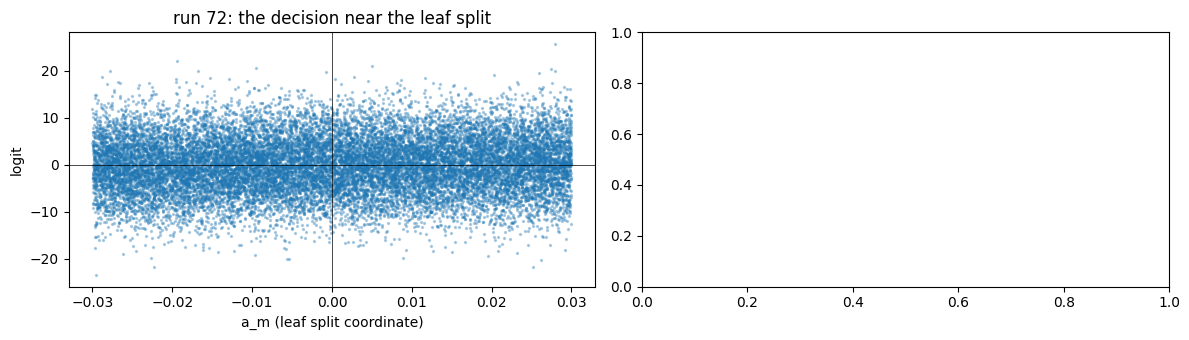

In [10]:
def logit_with(keep): return (h2 * keep[None, :]) @ readout
print("ablations (units of the removed levels silenced, the rest unchanged):")
for name, keep in [("all units", np.ones(N_UNITS)), ("level-3 units only", (NODE_LEVEL[unode] == 3).astype(float)), ("levels 2-3", (NODE_LEVEL[unode] >= 2).astype(float)), ("levels 1-3", (NODE_LEVEL[unode] >= 1).astype(float)), ("levels 0-2 (no leaf detectors)", (NODE_LEVEL[unode] < 3).astype(float))]:
    lg = logit_with(keep); print(f"  {name:32s}: test error {((lg >= 0) != (y > 0)).mean():.4f}, log loss {np.mean(np.logaddexp(0, -y * lg)):.4f}, logit rms {np.sqrt((lg ** 2).mean()):.1f}")
# the decision near the boundary
err = (logit >= 0) != (y > 0); bins = [0, 0.001, 0.003, 0.01, 0.03, 0.1, 1]
print("\nerror rate by |a_m| (the coordinate of the level-4 split the point reaches):", [(f"{bins[i]}-{bins[i + 1]}", round(float(err[(np.abs(am) >= bins[i]) & (np.abs(am) < bins[i + 1])].mean()), 4)) for i in range(len(bins) - 1)])
print(f"logit: corr with sign(a_m) {np.corrcoef(logit, np.sign(am))[0, 1]:.3f}, with a_m {np.corrcoef(logit, am)[0, 1]:.3f}; mean |logit| {np.abs(logit).mean():.1f}")
# per region: the pair's logit near the split is (b+ - b-)(x) + slope x a_m; the zero crossing and its spread across points (needs a (+, -) pair of leaf detectors for the region)
cross = []; served = {(int(r["region m"]), int(r["label served"])): int(r.unit) for _, r in t3.iterrows()} if len(t3) else {}
for m in range(15, 31):
    if (m, 1) not in served or (m, -1) not in served: continue
    up, um = served[(m, 1)], served[(m, -1)]; sel = (m_reached == m) & (np.abs(am) < 0.02)
    d = contrib[sel, up] + contrib[sel, um]; X = np.c_[np.ones(sel.sum()), am[sel]]; co = np.linalg.lstsq(X, d, rcond=None)[0]
    if co[1] == 0: continue
    bp = h1[sel] @ np.maximum(W2[up], 0) * readout[up]; bm = h1[sel] @ np.maximum(W2[um], 0) * readout[um]; cross.append({"m": m, "slope of pair logit in a_m": co[1], "zero crossing a_m*": -co[0] / co[1], "sd of crossing across x": np.std(bp + bm) / co[1]})
cross = pd.DataFrame(cross)
if len(cross): print(f"\nleaf pairs near the split ({len(cross)} regions with a (+, -) pair): slope {cross['slope of pair logit in a_m'].mean():.0f}, mean |crossing| {cross['zero crossing a_m*'].abs().mean():.5f}, spread of the crossing across points {cross['sd of crossing across x'].mean():.5f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5)); sel = np.abs(am) < 0.03
ax[0].scatter(am[sel][:20000], logit[sel][:20000], s=2, alpha=0.3); ax[0].axhline(0, color="k", lw=0.5); ax[0].axvline(0, color="k", lw=0.5); ax[0].set_xlabel("a_m (leaf split coordinate)"); ax[0].set_ylabel("logit"); ax[0].set_title(f"run {RUN}: the decision near the leaf split")
m_show = next((m for m in range(15, 31) if (m, 1) in served and (m, -1) in served), None)
if m_show is not None:
    u_plus, u_minus = served[(m_show, 1)], served[(m_show, -1)]; rr = m_reached == m_show
    ax[1].scatter(A[rr, m_show], contrib[rr, u_plus], s=3, alpha=0.4, label=f"unit {u_plus} (serves +)"); ax[1].scatter(A[rr, m_show], contrib[rr, u_minus], s=3, alpha=0.4, label=f"unit {u_minus} (serves -)")
    ax[1].set_xlabel(f"a_{m_show} on region {m_show}"); ax[1].set_ylabel("contribution readout x h"); ax[1].legend(); ax[1].set_title(f"the two leaf detectors of node {m_show}")
plt.tight_layout(); plt.show()


In [11]:
# The sharp-veto limit: rows snapped onto their closest +-u_j (tilt removed) and the vetoes (Weff < -1) scaled by K, everything else unchanged. With the trained (tilted) rows the same scaling cuts into the cells.
W1x = nrm[:, None] * pole[:, None] * U[top]; h1x = np.maximum(x @ W1x.T, 0)
units3 = [int(u) for u in t3.unit] if len(t3) else []; s3 = np.array([int(t3.set_index("unit").loc[u, "label served"]) for u in units3]); cell = {u: (int(t3.set_index("unit").loc[u, "region m"]), int(t3.set_index("unit").loc[u, "label served"])) for u in units3}
def leaf_activity(h2k): return np.mean([(h2k[(m_reached == cell[u][0]) & (np.sign(am) == cell[u][1]), u] > 0).mean() for u in units3]) if units3 else np.nan
print(f"rows -> exact normals, vetoes x K (full network / the {len(units3)} leaf detectors with a +-1 readout):")
for K in (1, 3, 10, 100, 1000):
    W2k = np.where(Weff < -1, K * W2, W2); h2k = np.maximum(h1x @ W2k.T, 0); lg = h2k @ readout; lg32 = h2k[:, units3] @ s3 if units3 else np.zeros(len(y))
    print(f"  K = {K:5d}: full error {((lg >= 0) != (y > 0)).mean():.5f}, log loss {np.mean(np.logaddexp(0, -y * lg)):.4f} | leaf units: error {((lg32 >= 0) != (y > 0)).mean():.5f}, best log loss over readout scales {min(np.mean(np.logaddexp(0, -y * c * lg32)) for c in (30, 100, 300, 1000, 3000)):.4f} | leaf units active on own (region, sign) {leaf_activity(h2k):.3f}")
for K in (1, 10):
    W2k = np.where(Weff < -1, K * W2, W2); h2k = np.maximum(h1 @ W2k.T, 0); lg = h2k @ readout
    print(f"  trained rows, vetoes x {K:2d}: full error {((lg >= 0) != (y > 0)).mean():.5f}, leaf units active on own (region, sign) {leaf_activity(h2k):.3f}")


rows -> exact normals, vetoes x K (full network / the 0 leaf detectors with a +-1 readout):


  K =     1: full error 0.41752, log loss 0.7837 | leaf units: error 0.49806, best log loss over readout scales 0.6931 | leaf units active on own (region, sign) nan


  K =     3: full error 0.41769, log loss 0.7417 | leaf units: error 0.49806, best log loss over readout scales 0.6931 | leaf units active on own (region, sign) nan
  K =    10: full error 0.41740, log loss 0.7243 | leaf units: error 0.49806, best log loss over readout scales 0.6931 | leaf units active on own (region, sign) nan
  K =   100: full error 0.41742, log loss 0.7180 | leaf units: error 0.49806, best log loss over readout scales 0.6931 | leaf units active on own (region, sign) nan
  K =  1000: full error 0.41741, log loss 0.7174 | leaf units: error 0.49806, best log loss over readout scales 0.6931 | leaf units active on own (region, sign) nan


  trained rows, vetoes x  1: full error 0.41773, leaf units active on own (region, sign) nan


  trained rows, vetoes x 10: full error 0.41776, leaf units active on own (region, sign) nan


**Findings (run 56, last epoch).**
- **The leaf detectors decide, the lower levels add margin.** Silencing everything but the 32 level-3 units leaves a working classifier
  (test error 1.8%, logit rms 13); silencing the leaf detectors instead leaves 24% error. Adding levels 2, 1 and 0 brings the error to
  0.97%, 0.71% and 0.37%; the lower levels contribute an offset that follows the leaf detectors' sign (level-2 total correlates 0.57 with
  the label). In run 53 the same ablation ladder read 1.1% -> 0.22% -> 0.20% -> 0.14% through the gated third layer; here the readout is
  linear, so the sign of the logit is exactly the sign of the units' weighted sum.
- **The decision near the leaf split is linear in a_m.** On region m the two detectors output their backgrounds and the one serving the
  wrong sign is cut by its cue veto, so the pair's logit is `(b_+ - b_-)(x) + 436 a_m` near a_m = 0: a line crossing zero at |a_m| of
  0.0003 on average, with a spread of 0.006 across points (the backgrounds' fluctuation divided by the slope; run 53: slope 300, spread
  0.0013). Errors live where |a_m| is small: 19% for |a_m| < 0.001, 1.8% for 0.001-0.003, 0.7% for 0.003-0.01, under 0.2% beyond
  0.03, which is the 0.37% test error (run 53: 0.13%, with the sharper crossing).
- **The sharp-veto limit.** Snap the rows onto exact +-u_j and scale only the vetoes by K, leaving backgrounds and readout alone: the
  full network's error goes 1.7% (K = 1: the tilt was load-bearing) -> 0.43% -> 0.11% -> 0.009% -> 0 for K = 3 / 10 / 100 / 1000, the
  32 leaf detectors with a +-1 readout likewise to 3 in 100k, and the log loss to 0.0004 / 0.0002. The crossing offset is
  (b_+ - b_-)/(veto slope), so it vanishes as 1/K, and the leaf units stay active on 100% of their cells. With the trained, tilted rows
  the same vetoes x10 cut into the cells (units active on 89% of their set, error 4.4%): the manufactured biases and the moderate vetoes
  are a matched pair, and exact normals with sharp vetoes are the clean limit of the same design.
- **The network therefore implements the tree as** `sum over the 32 (leaf, sign) cells of readout_(m,s) b(x) 1[x reaches m, sign(a_m) = s]`,
  with cell membership computed by vetoes on the wrong side of every split on the path, the sign by a veto on the wrong cue, the readout
  carrying the label sign, and the coarse units adding a sign-following margin. Compared with run 53 the same anatomy appears with the
  weights redistributed: larger probes and vetoes, smaller cues, a direct readout of 80 on the leaf detectors in place of the factorised
  one, and a boundary four times less sharp.


## 6. The paths: what each (row, unit) pair does, and how it changes during training

A path (row r, unit u) contributes `Wout[u] W2[u, r] (w_r . x)` to the logit on the points where both the row and the unit are active, a
linear function restricted to the path's active region. `layer_lenses.path_analysis.path_statistics` measures, for all 3720 paths on a
sample: the active fraction; the leaf-cell histogram of the active points (32 cells = (level-4 node, label sign); summarised by the share
of the largest cell and an entropy in bits, 5 bits = uniform); the path weight `|Wout W2| ||w_r||`; the mean and rms contribution on the
active set and its correlation with the label there. Rows are labelled by their closest normal and units by their design node, and each
path gets a tree relation (the row's node is the unit's own node, an ancestor, a descendant, or unrelated), so the designed paths (probe
-> own unit, cue -> the leaf detectors above it) can be followed as groups. `PATH_EPOCHS` chooses the epochs for the evolution plots.


In [12]:
from layer_lenses.path_analysis import path_statistics, path_group_summary, leaf_cells
N_PATH = 50_000; xp, yp = x[:N_PATH], y[:N_PATH]; cells_p = leaf_cells(xp, U)
def path_stats_at(e):
    Wa, W2a, Woa = (z[k][EPOCHS.index(e)].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__output_layer.weight"])
    Ca = Wa / np.linalg.norm(Wa, axis=1, keepdims=True) @ U.T; rn = np.abs(Ca).argmax(1); rp = np.sign(Ca[np.arange(len(Wa)), rn]).astype(int)
    return path_statistics(Wa, W2a, Woa, xp, yp, U, row_node=rn, row_pole=rp, unit_node=unode, cells=cells_p)
ps = path_stats_at(EPOCH); pd.set_option("display.max_rows", 60)
print(f"epoch {EPOCH}: {len(ps)} paths, {(ps.active_frac > 0).sum()} active on some point, {ps.path_weight.gt(1).sum()} with path weight > 1")
print("\nby (row kind, tree relation of the row's node to the unit's node, unit level): mean active fraction, path weight, rms contribution, label correlation, top-cell share, entropy; share of the total path weight")
display(path_group_summary(ps))


epoch 0: 3720 paths, 3720 active on some point, 120 with path weight > 1

by (row kind, tree relation of the row's node to the unit's node, unit level): mean active fraction, path weight, rms contribution, label correlation, top-cell share, entropy; share of the total path weight


n_paths  active_frac  path_weight  contrib_rms  corr_label  top_cell_share  entropy_bits  weight_share
row_kind relation   unit_level                                                                                                        
cue      descendant 0               128        0.250        0.173        0.012       0.074           0.045         4.975         0.057
                    1               128        0.250        0.173        0.013       0.077           0.045         4.977         0.057
                    2               128        0.250        0.173        0.013       0.079           0.044         4.978         0.057
                    3               128        0.250        0.173        0.013       0.082           0.044         4.978         0.057
         unrelated  1               128        0.250        0.115        0.008       0.077           0.045         4.977         0.038
                    2               384        0.250        0.115        0.009       0.079           0.044         4.978         0.114
                    3               896        0.250        0.115        0.009       0.082           0.044         4.978         0.265
probe    ancestor   1                 8        0.252        0.000        0.000       0.000           0.039         4.983         0.000
                    2                24        0.251        0.192        0.018      -0.006           0.039         4.983         0.012
                    3                80        0.250        0.058        0.006      -0.002           0.039         4.983         0.012
         descendant 0               116        0.249        0.080        0.008      -0.002           0.039         4.982         0.024
                    1               112        0.250        0.082        0.008      -0.002           0.039         4.983         0.024
                    2                96        0.250        0.048        0.005      -0.002           0.039         4.983         0.012
                    3                60        0.250        0.000        0.000       0.000           0.039         4.983         0.000
         own        0                 4        0.251        0.000        0.000       0.000           0.039         4.982         0.000
                    1                 4        0.250        1.155        0.112      -0.030           0.039         4.983         0.012
                    2                16        0.249        0.289        0.028      -0.009           0.039         4.983         0.012
                    3                36        0.249        0.128        0.012      -0.004           0.039         4.983         0.012
         unrelated  1               116        0.250        0.040        0.004      -0.001           0.039         4.983         0.012
                    2               344        0.250        0.067        0.006      -0.002           0.039         4.983         0.059
                    3               784        0.250        0.082        0.008      -0.003           0.039         4.983         0.166

probe -> own-unit paths (one per unit): path weight, active fraction, top cell share / entropy, label correlation (mean by unit level)


,path_weight,signed_path_weight,active_frac,top_cell_share,cell_entropy_bits,corr_label,contrib_rms
unit_level,,,,,,,
0,0.000,0.0,0.251,0.039,4.982,0.000,0.000
1,1.155,0.0,0.250,0.039,4.983,-0.030,0.112
2,0.289,0.0,0.249,0.039,4.983,-0.009,0.028
3,0.128,0.0,0.249,0.039,4.983,-0.004,0.012


cue -> ancestor-unit paths (the cue's leaf lies under the unit's node): by unit level


,path_weight,signed_path_weight,active_frac,top_cell_share,cell_entropy_bits,corr_label,contrib_rms
unit_level,,,,,,,
0,0.173,0.0,0.25,0.045,4.975,0.074,0.012
1,0.173,0.0,0.25,0.045,4.977,0.077,0.013
2,0.173,0.0,0.25,0.044,4.978,0.079,0.013
3,0.173,0.0,0.25,0.044,4.978,0.082,0.013


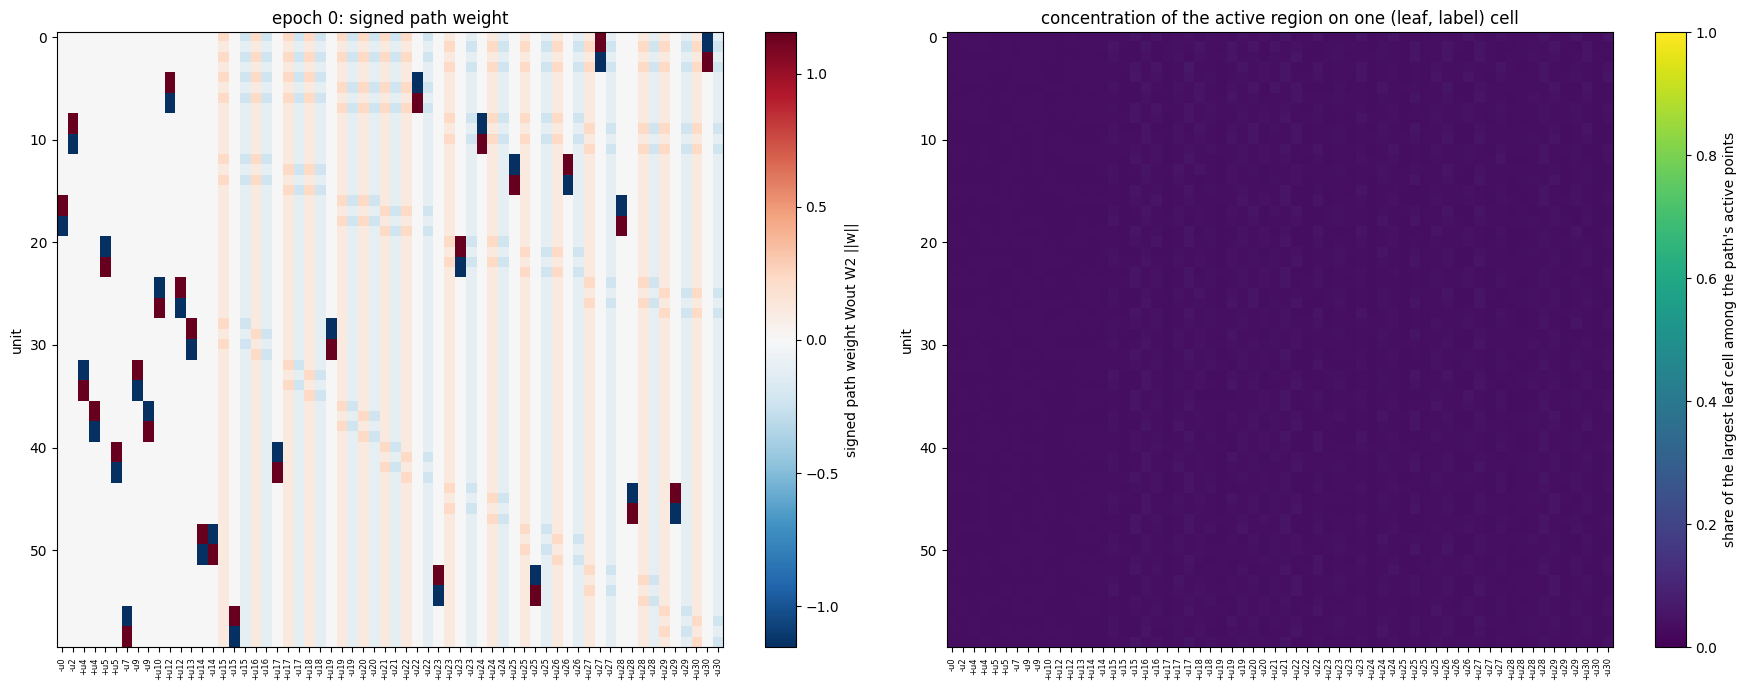

In [13]:
# the designed paths at EPOCH: probe -> its own units (relation own, probe rows) and cue -> units whose node is an ancestor of the cue's leaf
own = ps[(ps.row_kind == "probe") & (ps.relation == "own")].sort_values(["unit_level", "unit"]); cue_up = ps[(ps.row_kind == "cue") & (ps.relation == "descendant")]
print("probe -> own-unit paths (one per unit): path weight, active fraction, top cell share / entropy, label correlation (mean by unit level)")
display(own.groupby("unit_level")[["path_weight", "signed_path_weight", "active_frac", "top_cell_share", "cell_entropy_bits", "corr_label", "contrib_rms"]].mean().round(3))
print("cue -> ancestor-unit paths (the cue's leaf lies under the unit's node): by unit level")
display(cue_up.groupby("unit_level")[["path_weight", "signed_path_weight", "active_frac", "top_cell_share", "cell_entropy_bits", "corr_label", "contrib_rms"]].mean().round(3))
# heat maps at EPOCH: signed path weight and the top-cell share, units x rows (rows sorted by node)
order_r = np.lexsort((-pole, top)); M_w = ps.pivot(index="unit", columns="row", values="signed_path_weight").values[:, order_r]; M_c = ps.pivot(index="unit", columns="row", values="top_cell_share").values[:, order_r]
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
im = ax[0].imshow(M_w, cmap="RdBu_r", vmin=-np.nanmax(np.abs(M_w)), vmax=np.nanmax(np.abs(M_w)), aspect="auto"); plt.colorbar(im, ax=ax[0], label="signed path weight Wout W2 ||w||"); ax[0].set_title(f"epoch {EPOCH}: signed path weight")
im = ax[1].imshow(M_c, cmap="viridis", vmin=0, vmax=1, aspect="auto"); plt.colorbar(im, ax=ax[1], label="share of the largest leaf cell among the path's active points"); ax[1].set_title("concentration of the active region on one (leaf, label) cell")
for a in ax: a.set_xticks(range(N_ROWS)); a.set_xticklabels(rname[order_r], rotation=90, fontsize=6); a.set_ylabel("unit")
plt.tight_layout(); plt.show()


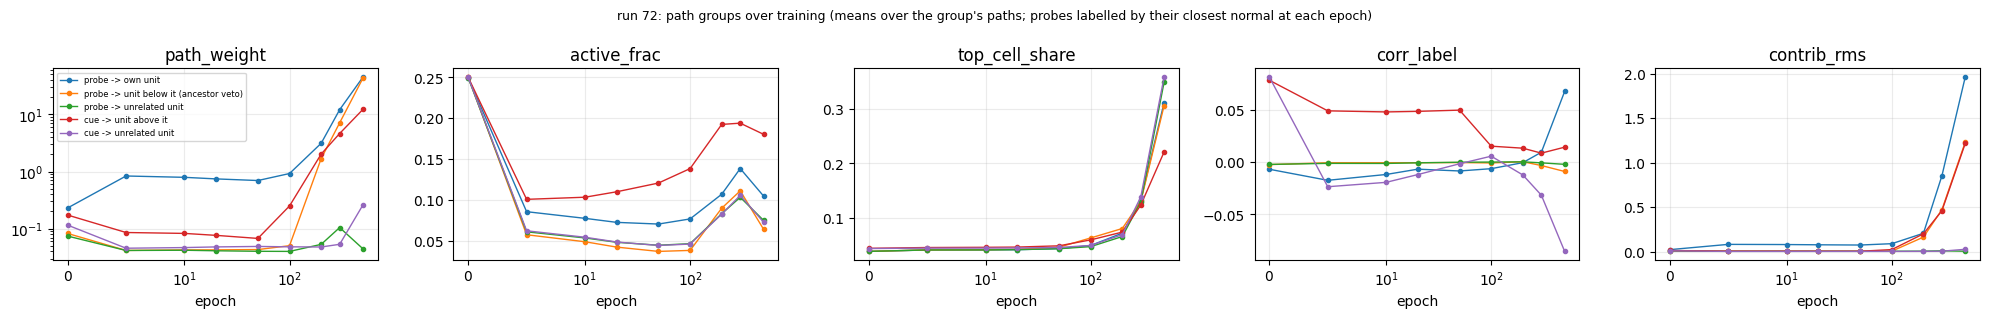

                                                         0      5      10     20     50     100    200     300     500
probe -> own unit                      path_weight     0.231  0.836  0.792  0.744  0.697  0.924  3.121  12.094  45.024
                                       active_frac     0.249  0.086  0.077  0.072  0.070  0.077  0.107   0.138   0.105
                                       top_cell_share  0.039  0.041  0.042  0.042  0.044  0.050  0.072   0.133   0.312
                                       corr_label     -0.007 -0.017 -0.012 -0.007 -0.009 -0.006 -0.001   0.009   0.067
                                       contrib_rms     0.022  0.081  0.079  0.077  0.074  0.089  0.206   0.854   1.965
probe -> unit below it (ancestor veto) path_weight     0.082  0.042  0.043  0.043  0.043  0.050  1.683   7.125  43.186
                                       active_frac     0.250  0.057  0.049  0.042  0.037  0.038  0.090   0.111   0.064
                                       top_cell_

In [14]:
# evolution over training of the main path groups
PATH_EPOCHS = sorted({e for e in (0, 5, 10, 20, 50, 100, 200, 300, 500, 700, 1000, 1500) if e in EPOCHS} | {EPOCHS[-1]})
groups = {"probe -> own unit": lambda t: (t.row_kind == "probe") & (t.relation == "own"), "probe -> unit below it (ancestor veto)": lambda t: (t.row_kind == "probe") & (t.relation == "ancestor"), "probe -> unrelated unit": lambda t: (t.row_kind == "probe") & (t.relation == "unrelated"),
          "cue -> unit above it": lambda t: (t.row_kind == "cue") & (t.relation == "descendant"), "cue -> unrelated unit": lambda t: (t.row_kind == "cue") & (t.relation == "unrelated")}
stats = ["path_weight", "active_frac", "top_cell_share", "corr_label", "contrib_rms"]; evo = {g: {s_: [] for s_ in stats} for g in groups}
for e in PATH_EPOCHS:
    t = path_stats_at(e)
    for g, f in groups.items():
        sub = t[f(t)]
        for s_ in stats: evo[g][s_].append(float(sub[s_].mean()))
fig, ax = plt.subplots(1, len(stats), figsize=(4 * len(stats), 3.2))
for k, s_ in enumerate(stats):
    for g in groups: ax[k].plot(PATH_EPOCHS, evo[g][s_], marker=".", lw=1, label=g)
    ax[k].set_title(s_); ax[k].set_xlabel("epoch"); ax[k].set_xscale("symlog", linthresh=10); ax[k].grid(alpha=0.25)
ax[0].set_yscale("log"); ax[0].legend(fontsize=6); plt.suptitle(f"run {RUN}: path groups over training (means over the group's paths; probes labelled by their closest normal at each epoch)", fontsize=9); plt.tight_layout(); plt.show()
print(pd.DataFrame({(g, s_): evo[g][s_] for g in groups for s_ in stats}, index=PATH_EPOCHS).round(3).T.to_string())


**Findings (first look, run 72, phase 1 of the symmetrised flow from run 70's init).** At init every path is active on a quarter of the
points with its active region spread over all 32 leaf cells (entropy 4.98 bits of 5), so no path is a detector. Over training the
designed probe -> own-unit paths grow from path weight 0.2 to 45 by epoch 500 while their active fraction falls to 0.1 and their active
region concentrates (top-cell share 0.04 -> 0.31); the probe -> unit-below-it paths, the ancestor vetoes, are 0.08 at init and 0.04 until
epoch 100 and then grow to 43 with the same concentration; the probe -> unrelated-unit paths stay at 0.04-0.1 throughout. The cue paths
carry the first-order label signal from the start (correlation 0.07-0.08 with the label on their active set, the same for every cue
path), and in this run they end as background: small weight, high entropy. In words: the network's weight moves onto the paths of the
tree (own node and ancestor vetoes), those paths become cell detectors, and everything off the tree stays at its initial size.
